

CORE OBJECTIVES :- 
1. EXPLORATORY DATA ANALYSIS (EDA)
       a.Identify kry trends, hidden patterns, and relationship
       b.Visualize disparities in diagnosis, lifestyle, treatment, and outcomes
       c.Highlight variations across countries, age groups , and cancer stages
2. Inferential & Predictive Analytics
   Using statistical methods, we'll explore ans answer critical healthcare questions:
       a.Determine the relationship between risk factors and cancer severity.
       b.Analyze the proportion of early- stage dignosis by cancer type
       c.Identify key predictors of cancer severity and survival years
       d.Explore the economic burdenof cancer treatment across different demographics and countries
       e.Assess wheather higher treatment cost is associated with longer survival
       f.Evaluate if higher cancer stages lead to greater treatment costs and reduced survival years
       g.Examine wheather higher genetic risk implies the negativ effects of smoking on cancer severity and survival outcomes.

3. Insight Extraction and Documentation
   a. For each major analysis, we will draw clear, evidence- backed inferences
   b. All finding will be systematically documented for future clinical, academic and operational use
   c.Each insight will be linked real- world implications -- to guide decision- making and policy formulation



In [ ]:
# import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [ ]:
# load the cancer data from 2015- 2024

data=pd.read_csv("C:/Users/chouh/Downloads/global_cancer_patients_2015_2024.csv")

In [ ]:
data

In [ ]:
data.info()

In [ ]:
data.duplicated().sum()

DESCRIPTIVE ANALYSIS

In [ ]:
# plotting for age column
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.kdeplot(data["Age"], fill=True, color="lightgreen")
plt.title("KDE plot for age")

plt.subplot(1,2,2)
sns.histplot(data["Age"],bins=30, kde=False, color="cyan")
plt.title("Histogram plot for age")

plt.tight_layout
plt.show()


In [ ]:
data["Age"].describe()

# INFERENCE

Range: 20 to 89 years
Mean Age: 54.42 years
Standard Deviation: 20.22
Interquartile Range(IQR) : 37 (Q1) to 72 (Q3)
This suggests a broad representation of both young and elderly patients in the dataset, which supports age- based comparative analysis 

In [ ]:
data

In [105]:
data["Gender"].isnull().sum()

0

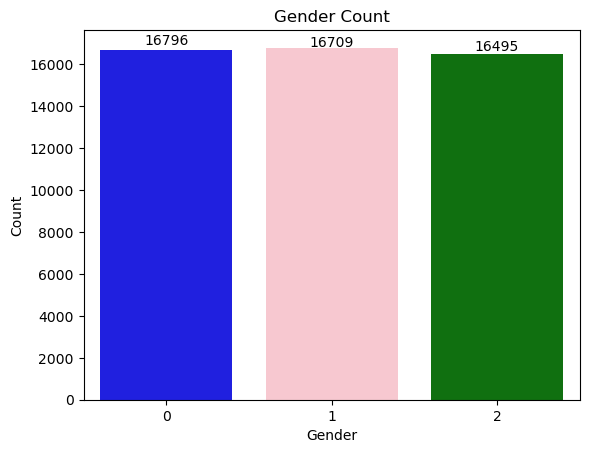

In [106]:
# Gender Column
data["Gender"].value_counts()

sns.barplot(x=data["Gender"].value_counts().index,
            y=data["Gender"].value_counts().values,
            palette=["blue", "pink", "green"]
           )
for i , v in enumerate(data["Gender"].value_counts()):
    plt.text(i,v,str(v), ha="center",va="bottom")

plt.title("Gender Count")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

In [107]:
data["Gender"].value_counts()

Gender
1    16796
0    16709
2    16495
Name: count, dtype: int64

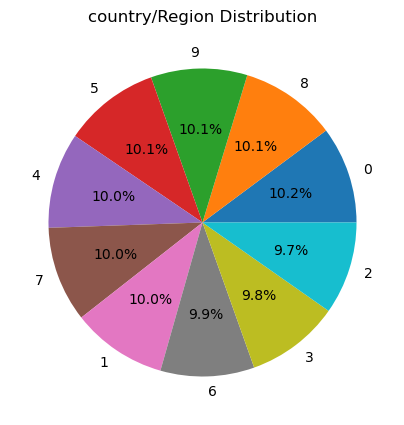

In [108]:
# Countries distribution 
country_counts= data["Country_Region"].value_counts()

plt.figure(figsize=(5,5))
plt.pie(x=country_counts.values,
       labels=country_counts.index,
       autopct='%1.1f%%')

plt.title("country/Region Distribution")
plt.show()


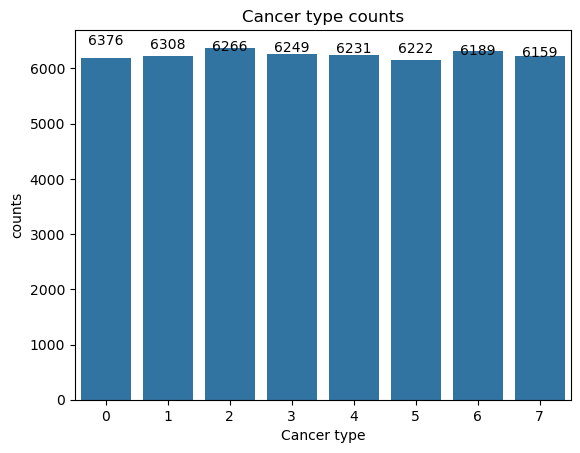

In [109]:
# Cancer Type
data["Cancer_Type"].value_counts()

sns.barplot(x=data["Cancer_Type"].value_counts().index,
            y=data["Cancer_Type"].value_counts().values)

for i, v in enumerate(data["Cancer_Type"].value_counts()):
    plt.text(i,v, str(v), ha="center", va="bottom")


plt.title("Cancer type counts")
plt.xlabel("Cancer type")
plt.ylabel("counts")
plt.show()

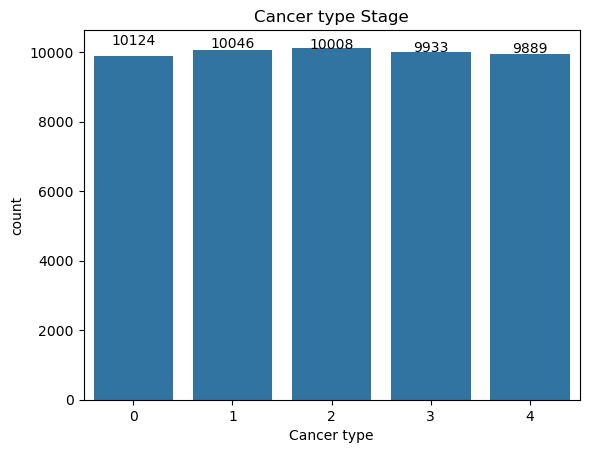

In [110]:
# Cancer Stage
data["Cancer_Stage"].value_counts()

sns.barplot(x=data["Cancer_Stage"].value_counts().index,
           y=data["Cancer_Stage"].value_counts().values)

for i, v in enumerate(data["Cancer_Stage"].value_counts()):
    plt.text(i,v , str(v), ha="center",va="bottom")

plt.title("Cancer type Stage")
plt.xlabel("Cancer type")
plt.ylabel("count")
plt.show()

Cancer stage have 5 stages with value ranging from 0 to 4 , with stage 2 the most common one, and each stage have same number of 
data points under its label

In [111]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Patient_ID             50000 non-null  object 
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  int64  
 3   Country_Region         50000 non-null  int64  
 4   Year                   50000 non-null  int64  
 5   Genetic_Risk           50000 non-null  float64
 6   Air_Pollution          50000 non-null  float64
 7   Alcohol_Use            50000 non-null  float64
 8   Smoking                50000 non-null  float64
 9   Obesity_Level          50000 non-null  float64
 10  Cancer_Type            50000 non-null  int64  
 11  Cancer_Stage           50000 non-null  int64  
 12  Treatment_Cost_USD     50000 non-null  float64
 13  Survival_Years         50000 non-null  float64
 14  Target_Severity_Score  50000 non-null  float64
dtypes:

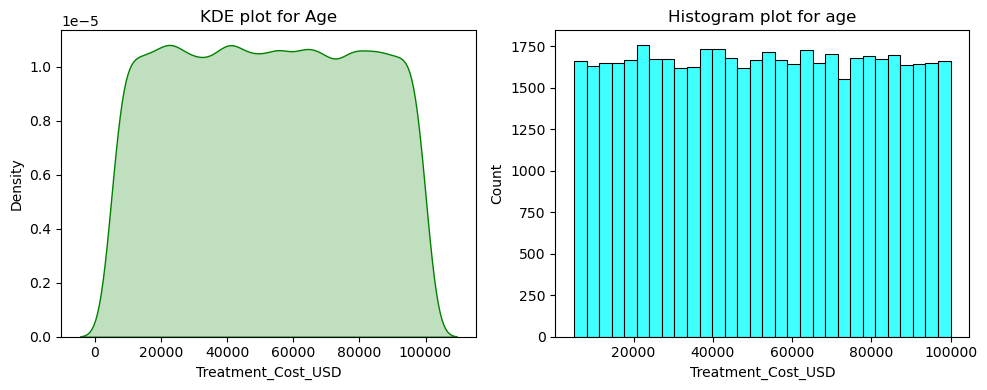

In [112]:
# plotting for treatment cost

# plotting for the age column
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.kdeplot(data["Treatment_Cost_USD"], fill=True, color="green")
plt.title("KDE plot for Age")

plt.subplot(1,2,2)
sns.histplot(data["Treatment_Cost_USD"],bins=30, kde=False, color= "cyan")
plt.title("Histogram plot for age")

plt.tight_layout()
plt.show()

In [113]:
data["Treatment_Cost_USD"].describe()

count    50000.000000
mean     52467.298239
std      27363.229379
min       5000.050000
25%      28686.225000
50%      52474.310000
75%      76232.720000
max      99999.840000
Name: Treatment_Cost_USD, dtype: float64

Treatment cost USD have no skewness, and there are almost snae number of the data points each bin as observed by histogram

In [114]:
# ANALYZING THE RISK FACTORS
column_of_interests= ['Genetic_Risk','Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']

summary= data[column_of_interests].agg(['mean','std','max', 'min'])
summary

,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level
mean,5.001698,5.010126,5.010880,4.989826,4.991176
std,2.885773,2.888399,2.888769,2.881579,2.894504
max,10.000000,10.000000,10.000000,10.000000,10.000000
min,0.000000,0.000000,0.000000,0.000000,0.000000


These variable have nearly identical means and standard deviations , indicating thery were likely designd on the same standarized scale.
They are essential in studying interaction effects (eg. genetic risk *smoking) o survival)

DETERMINE THE RELATIONSHIP BETWEEN RISK FACOTRS AND CANCER SEVERITY

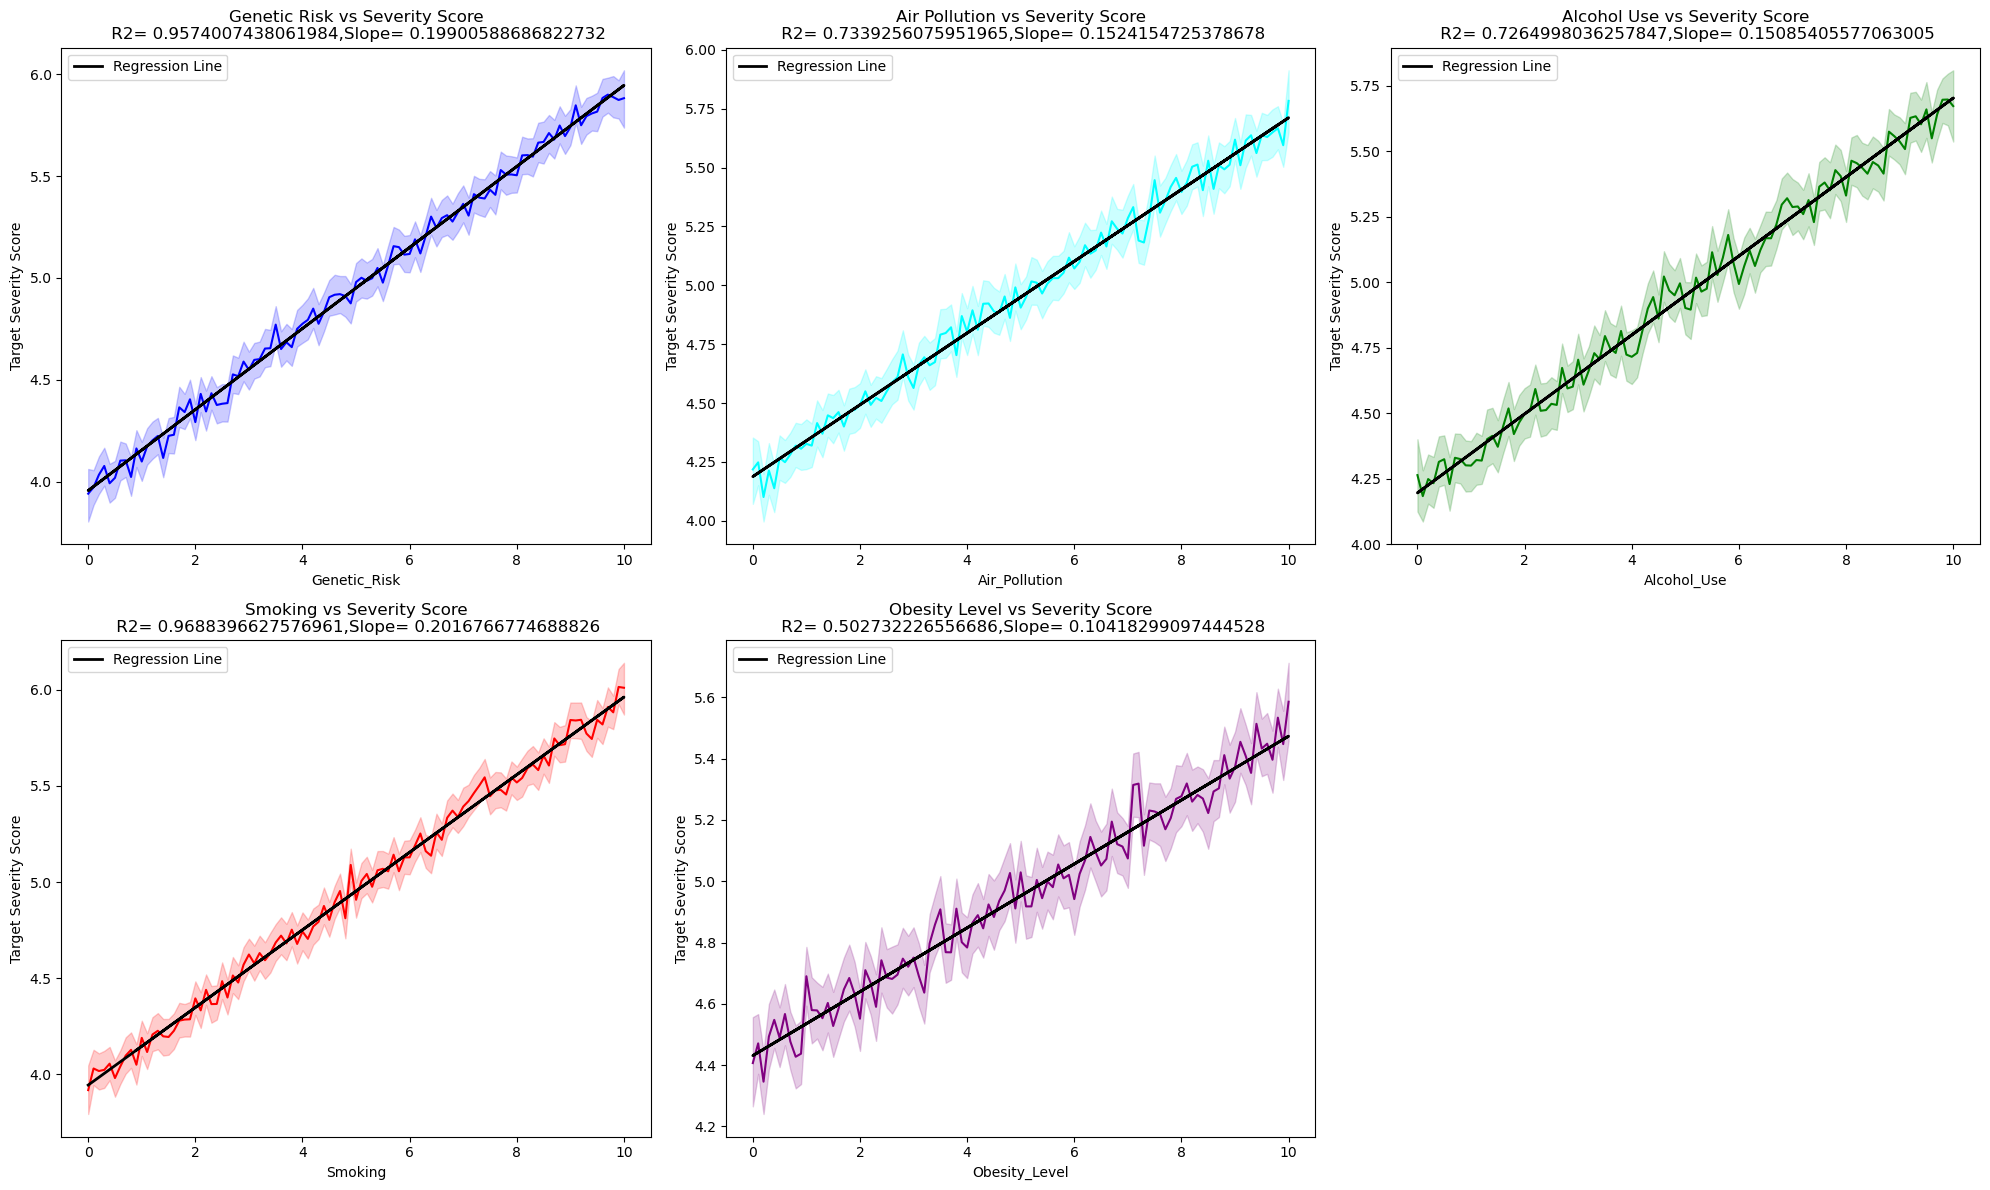

In [115]:
from scipy.stats import linregress

risk_factors= ['Genetic_Risk','Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']
titles= ['Genetic Risk','Air Pollution', 'Alcohol Use', 'Smoking', 'Obesity Level']
colors= ['blue', 'cyan', 'green','red','purple']


plt.figure(figsize=(20,12))
for i ,(factor, title, color) in enumerate(zip(risk_factors, titles, colors),1):
    
    plt.subplot(2,3,i)
    x=data[factor]
    y=data["Target_Severity_Score"]
    slope, intercept, r_value, p_value, std_err=linregress(x,y)
    r_squared= r_value*2

    sns.lineplot(x=factor, y="Target_Severity_Score",data=data, color=color)
    plt.plot(x,x*slope+intercept, color="black", linewidth=2,label="Regression Line")
    plt.title(f"{title} vs Severity Score\n R2= {r_squared},Slope= {slope}")
    plt.xlabel(factor)
    plt.ylabel("Target Severity Score")
    plt.legend()

# line = mx+c



plt.tight_layout()
plt.show()

To understand the conribution of various risk factors to cancer severity , line plots were generated for five primary variables : Genetic RIsk, Air, Pollution, Alocohol Use, Smoking and obesity level, plotted against the Target Severity Score.
All graphs reveal a positive realtionship , including indicating that as the level of a particular rik factor increases, the corresponding severity of the condition also tends to rise. However, the degree of association measured  by the slpoe and tightness of the confidence interval-varies across the facotrs.

Genetic Risk vs Target Severity Score 
R^2= 0.23
A weak linear relationship. Only 23% of the variability in the Target_Severity_Score can be explained by Genetic_risk. This suggests that other factors likely play a larger role in a influencing the severity score.
Slpoe = 0.20
A positive slope indicates that as Genetic_Risk increases, the Target_Severity_Score also tends to increase. For each unit inccrese in Genetic_Risk,
the Target_Severity_Score increases by 0.20 units. However, because the R^2 iss relatively low, this trend is not very consistent across the data.

Air Pollution vs Target Severity Score
R^2 = 0.13:
A very weak relationship only 13% of the variance in Target_Severity_Score can be explained by Air_pollution, meaning that this factor has limited effect
on the target variable 
Slope= 0.15:
A positive slpoe means that air pollution increases , the severity score slightly increases. But due to the low R^2 , this relationship is weak and 
unreliable as a predictor for the target severity.

Alcohol vs Target severity score
R^2= 0.13:
Similarity , the realtionship between the Alcohol_Use and target severity increases is also weak , only 13% of the variation in the target score is explained by alcohol use.

Slope: 0.15:
HTe positive slope indicates that increased alcohol use correlates with slight increase in target severity. However, like air pollution , weak R^2 suggests other factors have much stronger influence on the target.

Smoking vs Target Severity Score
R^2 = 0.23:
A weak relationship, similar to Genetic_Risk .Smoking explains only 23% of the variance in the target score, leaving the majority of the variation to 
be explained by the other factors.
Slope =0.20:
the positive slope implies that smoking increases, the target severity score  increases as well. the relationship is similar to that of genetic risk, but with a weak linear association (low R^2).

Obesity Level vs Target Severity Score
R^2= 0.06
THe weakest realtionship among all factors. Only 6% of the variation in the target score is explained by the obesity level, suggesting that obesity has a minimum effect on the target varible 
Slope = 0.10:
A positive slope , indicating a slight increase in the severity score as a obesity level increses. However, due to the very low R^2, this is a weak and unreliable relationship.

Key takewys:
Weak Linear Relationship :

The R^2 vlaues for all the risk factors are relatively low, ranging form 0.06 to 0.23. This indicates that while there is some relationship between these
risk factors and the Target_Severity_Score, it is weak. These factors done alone do not explain much of the variation in the target variable

Positive Trends:

All the slope vlaues are positives, suggesting that as esach risk factors increases, the Target_Severity_Score tends to increase as well. However, because the R^2 vallues is low this increase is not strongly consistent across all data points.

Other Influences:

The low R^2 values that other, unmeasured factors are likely contributing to the variation in Target_Severity_Score. The risk factors you examined are only weakly correalted with the target and are not reliable predictors on their own.

Next Steps:

Given the weak explanatory power of these individual facotrs, it might br useful to explore other varialbe or more models that could account for more of the variation in the Target_Severity_Score. This could include interactions between risk factors, adding new features , or applying more sophesticated regression techniques.
                                

ANALYZE THE PROPORTION OF EARLY STAGE DIAGNOSIS BY CANCER TYPE 

In [116]:
data['Cancer_Type'].unique()

array([5, 3, 0, 2, 7, 1, 6, 4], dtype=int64)

In [117]:
stage_count=data[data["Cancer_Type"]=="Lung"]["Cancer_Stage"].value_counts()
early_stage_sum= stage_count.get("Stage 0",0)+ stage_count.get("Stage I",0)
total_sum= stage_count.sum()
proportion=(early_stage_sum/total_sum)*100
print(f"proportion of lungs cancer diagnosed at stage 0 and stage 1 : {proportion}")

proportion of lungs cancer diagnosed at stage 0 and stage 1 : nan


In [118]:
stage_count= data[data["Cancer_Type"]=="Leukemia"]["Cancer_Stage"].value_counts()
early_stage_sum= stage_count.get("Stage 0",0)+ stage_count.get("Stage I",0)
total_sum= stage_count.sum()
proportion=(early_stage_sum/total_sum)*100
print(f"proportion of Leukemia cancer diagnosed at stage 0 and stage 1 : {proportion}")

proportion of Leukemia cancer diagnosed at stage 0 and stage 1 : nan


In [119]:
stage_count= data[data["Cancer_Type"]=="Breast"]["Cancer_Stage"].value_counts()
early_stage_sum= stage_count.get("Stage 0",0)+ stage_count.get("Stage I",0)
total_sum= stage_count.sum()
proportion=(early_stage_sum/total_sum)*100
print(f"proportion of Breast cancer diagnosed at stage 0 and stage 1 : {proportion}")

proportion of Breast cancer diagnosed at stage 0 and stage 1 : nan


In [120]:
stage_count= data[data["Cancer_Type"]=="Colon"]["Cancer_Stage"].value_counts()
early_stage_sum= stage_count.get("Stage 0",0)+ stage_count.get("Stage I",0)
total_sum= stage_count.sum()
proportion=(early_stage_sum/total_sum)*100
print(f"proportion of Colon cancer diagnosed at stage 0 and stage 1 : {proportion}")

proportion of Colon cancer diagnosed at stage 0 and stage 1 : nan


In [121]:
stage_count= data[data["Cancer_Type"]=="Skin"]["Cancer_Stage"].value_counts()
early_stage_sum= stage_count.get("Stage 0",0)+ stage_count.get("Stage I",0)
total_sum= stage_count.sum()
proportion=(early_stage_sum/total_sum)*100
print(f"proportion of Skin cancer diagnosed at stage 0 and stage 1 : {proportion}")

proportion of Skin cancer diagnosed at stage 0 and stage 1 : nan


In [122]:
stage_count= data[data["Cancer_Type"]=="Cervical"]["Cancer_Stage"].value_counts()
early_stage_sum= stage_count.get("Stage 0",0)+ stage_count.get("Stage I",0)
total_sum= stage_count.sum()
proportion=(early_stage_sum/total_sum)*100
print(f"proportion of Cervical cancer diagnosed at stage 0 and stage 1 : {proportion}")

proportion of Cervical cancer diagnosed at stage 0 and stage 1 : nan


In [123]:
stage_count= data[data["Cancer_Type"]=="Prostate"]["Cancer_Stage"].value_counts()
early_stage_sum= stage_count.get("Stage 0",0)+ stage_count.get("Stage I",0)
total_sum= stage_count.sum()
proportion=(early_stage_sum/total_sum)*100
print(f"proportion of Prostate cancer diagnosed at stage 0 and stage 1 : {proportion}")

proportion of Prostate cancer diagnosed at stage 0 and stage 1 : nan


In [124]:
stage_count= data[data["Cancer_Type"]=="Liver"]["Cancer_Stage"].value_counts()
early_stage_sum= stage_count.get("Stage 0",0)+ stage_count.get("Stage I",0)
total_sum= stage_count.sum()
proportion=(early_stage_sum/total_sum)*100
print(f"proportion of Liver cancer diagnosed at stage 0 and stage 1 : {proportion}")

proportion of Liver cancer diagnosed at stage 0 and stage 1 : nan


The analysis demonstrates that early_stage diagnosis for various cancer types is relatively widespread , with most cancers having an early diagnosis
rate between 38.43 and 40.16% .Liver Cancer shows the highest proportion, while lung cancer shows the lowest. these finding suggest that while screening
and diagnostic methods are effective, improvements cna still be made, particularly in llung cancer detection.

Further research into screening strategies, early intervention, and use of advanced diagnostics technologies could help increase the proportion of 
early stage diagnosis, ultimately leading to better survival rates and outcomes for cancer patients. The small variations across the cancer types indicate
that, in general , healthcare systems may need to focus on enhancing early detection uniformly, with targeted efforts specific gaps in detection, particularly 
for cancer like lung cancer.

# Identify Key predictors of cancer severity and survival years

In [125]:
 # corelation analysis and random forest.
# individual how each output affecting. 

In [126]:
#without useing the libraries
# first find out the features 

In [127]:
features = ['Age','Genetic_Risk','Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']

targets= ["Survival_Years","Target_Severity_Score"]

# pearson and spearman correlation

pearson_corr= data[features+targets].corr(method='pearson')
spearman_corr=data[features+targets].corr(method='spearman')

# slice out the linear realtion with target variables
pearson_result= pearson_corr[targets]
spearman_result=spearman_corr[targets]


# combine both 
correlation_df=pd.concat([pearson_result, spearman_result],axis=1, keys=["Pearson","Spearman"]) 
correlation_df

Pearson                             Spearman  \
                      Survival_Years Target_Severity_Score Survival_Years   
Age                        -0.000147             -0.001481      -0.000149   
Genetic_Risk                0.001708              0.478700       0.001684   
Air_Pollution               0.000893              0.366963       0.000841   
Alcohol_Use                -0.000527              0.363250      -0.000543   
Smoking                     0.001371              0.484420       0.001372   
Obesity_Level               0.009771              0.251366       0.009780   
Survival_Years              1.000000              0.004161       1.000000   
Target_Severity_Score       0.004161              1.000000       0.003431   

                                             
                      Target_Severity_Score  
Age                               -0.002076  
Genetic_Risk                       0.472193  
Air_Pollution                      0.357528  
Alcohol_Use                        0.354694  
Smoking                            0.477881  
Obesity_Level                      0.243152  
Survival_Years                     0.003431  
Target_Severity_Score              1.000000

In [128]:
pearson_corr[targets]

,Survival_Years,Target_Severity_Score
Age,-0.000147,-0.001481
Genetic_Risk,0.001708,0.478700
Air_Pollution,0.000893,0.366963
Alcohol_Use,-0.000527,0.363250
Smoking,0.001371,0.484420
Obesity_Level,0.009771,0.251366
Survival_Years,1.000000,0.004161
Target_Severity_Score,0.004161,1.000000


In [129]:
pearson_corr

,Age,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Survival_Years,Target_Severity_Score
Age,1.000000,0.002229,0.001101,-0.004130,0.001734,-0.002706,-0.000147,-0.001481
Genetic_Risk,0.002229,1.000000,-0.004492,-0.002558,-0.003718,0.003522,0.001708,0.478700
Air_Pollution,0.001101,-0.004492,1.000000,0.003511,0.003549,0.006507,0.000893,0.366963
Alcohol_Use,-0.004130,-0.002558,0.003511,1.000000,-0.002938,0.007425,-0.000527,0.363250
Smoking,0.001734,-0.003718,0.003549,-0.002938,1.000000,0.005828,0.001371,0.484420
Obesity_Level,-0.002706,0.003522,0.006507,0.007425,0.005828,1.000000,0.009771,0.251366
Survival_Years,-0.000147,0.001708,0.000893,-0.000527,0.001371,0.009771,1.000000,0.004161
Target_Severity_Score,-0.001481,0.478700,0.366963,0.363250,0.484420,0.251366,0.004161,1.000000


In [ ]:
# random forest for target severity score

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score

# converting categorial columns to numerical columns
categorical_cols= ["Gender","Country_Region","Cancer_Type","Cancer_Stage"]
for col in categorical_cols:
    le=LabelEncoder()
    data[col]=le.fit_transform(data[col])

# preparing feaatures and input

X=data.drop(columns=["Patient_ID","Survival_Years","Target_Severity_Score","Treatment_Cost_USD"])
y_severity= data["Target_Severity_Score"]

# train test split
X_train_s, X_test_s, y_train_s,y_test_s= train_test_split(X,y_severity, test_size=0.2, random_state=42)

# train the model

model=RandomForestRegressor(n_estimators=200,max_depth= None, min_samples_split=2, min_samples_leaf=1, random_state=40)

model.fit(X_train_s, y_train_s)


# evaluate the model

train_r2_severity= r2_score(y_train_s, model.predict(X_train_s))
test_r2_severity=r2_score(y_test_s, model.predict(X_test_s))
 

In [ ]:
print(train_r2_severity)
print(test_r2_severity)

In [ ]:
feature_importance_severity=pd.Series(model.feature_importances_,index=X.columns,).sort_values(ascending=True)

# plotting of importnace features

plt.figure(figsize=(10,6))
feature_importance_severity.plot(kind="bar", color="skyblue")
plt.title("Feature Importance for Target Severity Score (Random Forest)")
plt.xlabel("Features")
plt.ylabel("importance score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



Feature Importance Interpretation

Smoking 0.2336 Most important predictor of severity socre. The more a patient smokes, the higher their severity tends to be.
Genetic_Risk 0.2286 Strong genetic prediposition is nearly as important as smoking.
Treatment_Cost_USD 0.2133 Higher Treatment costs are associated with more severe conditions.
Alocohol_Use 0.1291 Alcohol also plays a significant role.
Air_Pollution 0.1271 Enviornmental factors-patients in more polluted areas have worse severity score.
Obesity_level 0.0576 Has an effect , but much smaller.
Age to Gender <0.01 Very low importance, these donn't explain much variation in severity score.

E.g. , Smoking, Genetic Risk, Air Pollution are major influences. This tells you where interventions might reduce severity.


In [ ]:
# for survival
# random forest for target severity score

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score

# converting categorial columns to numerical columns
categorical_cols= ["Gender","Country_Region","Cancer_Type","Cancer_Stage"]
for col in categorical_cols:
    le=LabelEncoder()
    data[col]=le.fit_transform(data[col])

# preparing feaatures and input

X=data.drop(columns=["Patient_ID","Survival_Years","Target_Severity_Score","Treatment_Cost_USD"])
y_severity= data["Survival_Years"]

# train test split
X_train_s, X_test_s, y_train_s,y_test_s= train_test_split(X,y_severity, test_size=0.2, random_state=40)

param_grid={
    'n_estimators': [100,200],
    'max_depth': [5,10, None],
    'min_samples_split': [2,5],
    'min_samples_leaf': [1,2]
}


# train the model
model=RandomForestRegressor (random_state=40)
GSC= GridSearchCV (model, param_grid, cv=3, scoring="r2", n_jobs=-1)
GSC.fit (X_train_s, y_train_s)

best_ef_severity= GSC.best_estimators_

# evaluate the model

train_r2_severity= r2_score(y_train_s, model.predict(X_train_s))
test_r2_severity=r2_score(y_test_s, model.predict(X_test_s))
 

In [ ]:
print(train_r2_severity)
print(test_r2_severity)

<Axes: xlabel='Survival_Years', ylabel='Count'>

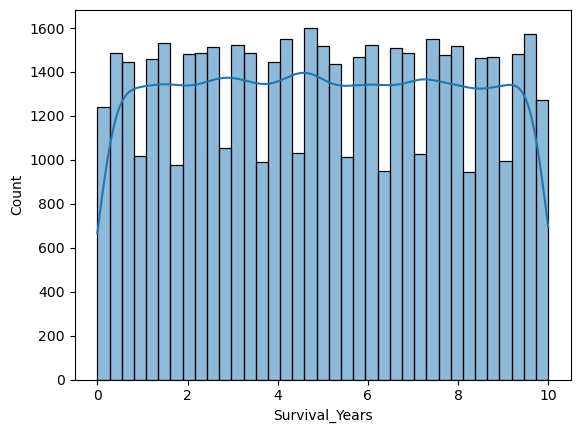

In [101]:
import seaborn as sns
sns.histplot(data["Survival_Years"], kde=True)

In [136]:
data.corr(numeric_only=True)["Survival_Years"].sort_values(ascending=True)

Gender                  -0.007121
Cancer_Stage            -0.003014
Cancer_Type             -0.001717
Alcohol_Use             -0.000527
Treatment_Cost_USD      -0.000429
Age                     -0.000147
Year                     0.000018
Air_Pollution            0.000893
Smoking                  0.001371
Genetic_Risk             0.001708
Target_Severity_Score    0.004161
Country_Region           0.005121
Obesity_Level            0.009771
Survival_Years           1.000000
Name: Survival_Years, dtype: float64

# Explore the economic burden of cancer treatment across different demographics and countries 

In [138]:
data

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,1,8,2021,6.4,2.8,9.5,0.9,8.7,5,3,62913.44,5.9,4.92
1,PT0000001,34,1,3,2021,1.3,4.5,3.7,3.9,6.3,3,0,12573.41,4.7,4.65
2,PT0000002,80,1,6,2023,7.4,7.9,2.4,4.7,0.1,0,2,6984.33,7.1,5.84
3,PT0000003,40,1,8,2015,1.7,2.9,4.8,3.5,2.7,2,1,67446.25,1.6,3.12
4,PT0000004,43,0,1,2017,5.1,2.8,2.3,6.7,0.5,7,3,77977.12,2.9,3.62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,PT0049995,80,1,6,2023,2.3,7.5,2.8,3.8,2.9,3,0,71463.70,1.0,3.63
49996,PT0049996,40,0,9,2018,6.4,3.5,2.9,9.0,9.8,2,1,49619.66,0.4,6.03
49997,PT0049997,74,1,6,2015,6.2,1.6,8.7,4.7,4.0,0,0,5338.25,2.7,6.02
49998,PT0049998,21,1,1,2018,4.0,6.5,7.6,8.6,8.1,4,4,45100.47,7.5,6.54


In [139]:
df=data.copy()

In [162]:
country_gender_cost=data.groupby(["Country_Region","Gender"])["Treatment_Cost_USD"].mean().reset_index()

In [163]:
country_gender_cost

,Country_Region,Gender,Treatment_Cost_USD
0,0,0,52301.781302
1,0,1,52928.509540
2,0,2,52629.969316
3,1,0,52484.894936
4,1,1,52937.613970
5,1,2,52186.267723
6,2,0,52358.507421
7,2,1,52846.880795
8,2,2,52559.389020
9,3,0,52438.973622


In [164]:
data["Age_Group"]=pd.cut(data["Age"],bins=[0,30,45,60,75,100],labels=["0-30","31-45","46-60","61-75","76+"])

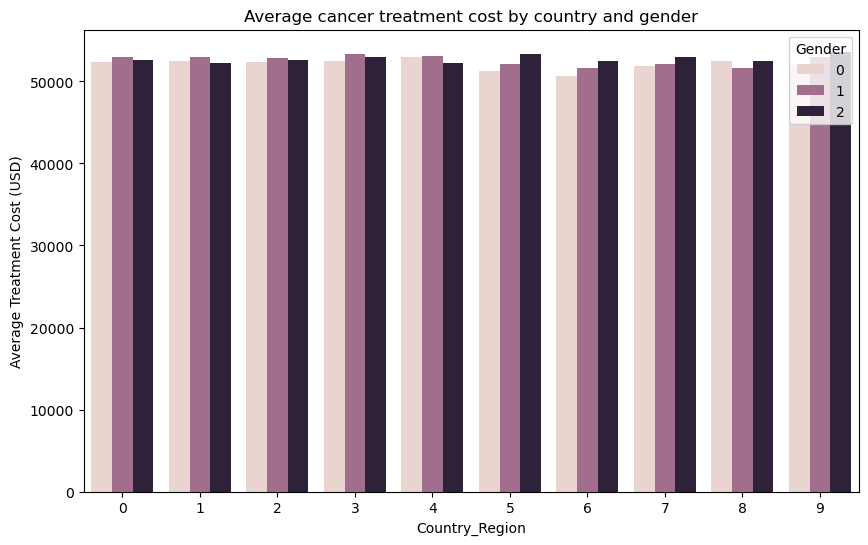

In [170]:
country_gender_cost = (
    data.groupby(["Country_Region", "Gender"])["Treatment_Cost_USD"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=country_gender_cost, x="Country_Region", y="Treatment_Cost_USD", hue="Gender")
plt.title("Average cancer treatment cost by country and gender")
plt.ylabel("Average Treatment Cost (USD)")
plt.show()

In [171]:
country_age_cost= data.groupby(["Country_Region","Age_Group"])["Treatment_Cost_USD"].mean().reset_index()

In [174]:
heatmap_data= country_age_cost.pivot(index="Age_Group",columns="Country_Region",values="Treatment_Cost_USD")

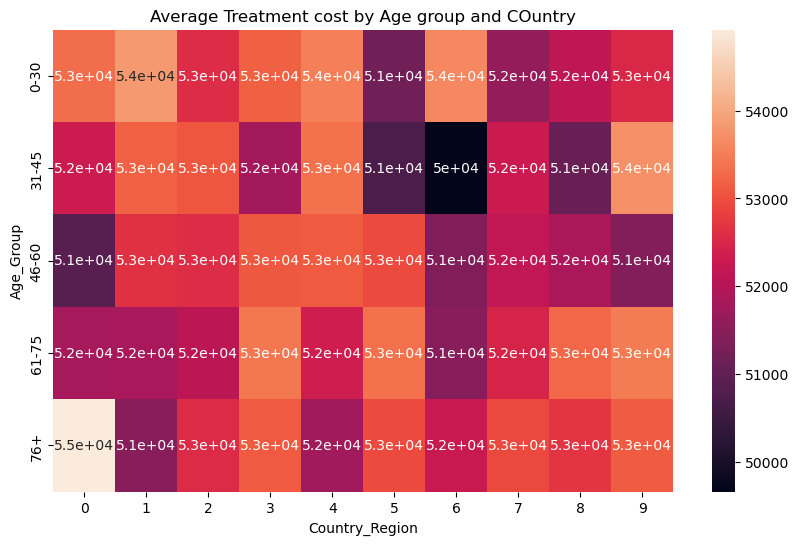

In [177]:
plt.figure(figsize=(10,6))
sns.heatmap(heatmap_data, annot= True)
plt.title("Average Treatment cost by Age group and COuntry")
plt.show()

Geographic Disparities in Economic Burden :
cancer treatment costs are significantly higher in developed nations such as USA, Australia , and China, revealing the heavy financial load advanced 
healthcare systems, Meanwhile, couontries like India and pakistan exhibit comparatively lower cost, likely due to lower healthcare pricing structures
or limited accessto advanced treatment. This highlights a clear global inequality in healthcare affordability that can intestify financial strain depending on a patient's country or residence.

Gender- Based Cosr Pattern are Uniform :
Across all countries, gender-based differences in a average treatment cost are minimal, suggesting no major gender bias in pricing or access to cancer care. This uniformity may reflect standarization in treatment protocols or equitable healthcare policies, but it also points to the fact that the financial impact of cancer is universal across the genders.

Age-Related Escalation in Treatment costs :
Treatment costs tend to rise with age, particularly for those aged 61 and above. This trend is especially evident in countries like Australia and the USA, where odler age groups face sharply higher costs. The increased financial burden in these groups could be due to more intensive care needs, multiple comorbidities , or prolonged treatments. This pattern underlies the vulnerability of elderly poppulations and the pressing need for targeted support for senior citizens.

Role of Healthcare systems in cost variation: 
Countries with robust public healthcare systems-such as Canada,Germany and the UK-show relatively stable treatment cost acorss age groups, reflecting the benefits of healthcare subsidies ot coverage. This consistancy rrinforces the importance of goverment intervention and universal healthcare in mitigating financial disparities in cancer treatment.


# Assess whether higher treatment cost associated with longer survival


Null Hypothesis (H0) : - There is no corrleation between treatment cost and survival years.
Alternatie Hypothesis : - There is a correlation (positive and negative ) between treatment cost and survival years.


In [185]:
from scipy.stats import pearsonr, spearmanr
x=data["Treatment_Cost_USD"]
y=data["Survival_Years"]


# performing pearson correlation test

pearson_corr, pearson_p= pearsonr(x,y)
print(f"Pearson Correaltion Coefficient : {pearson_corr}")
print(f"Pearson P-Value : {pearson_p}")

# Spearman Correlation test:

spearman_corr, spearman_p= spearmanr(x,y)
print(f"Spearman Correaltion Coefficient : {spearman_corr}")
print(f"Spearman P-Value : {spearman_p}")



alpha = 0.05


def interpret_corr(corr,p,method):
    if p<alpha:
        print(f"{method}, we reject the null hypothesis")
    else:
        print(f"{method},we failed to reject null hypothesis")

interpret_corr(pearson_corr, pearson_p, "Pearson")
interpret_corr(spearman_corr, spearman_p, "Spearman")


Pearson Correaltion Coefficient : -0.0004294054283021494
Pearson P-Value : 0.9235082012963326
Spearman Correaltion Coefficient : -0.0004454737292549569
Spearman P-Value : 0.9206551702014918
Pearson,we failed to reject null hypothesis
Spearman,we failed to reject null hypothesis


<Axes: xlabel='Treatment_Cost_USD', ylabel='Survival_Years'>

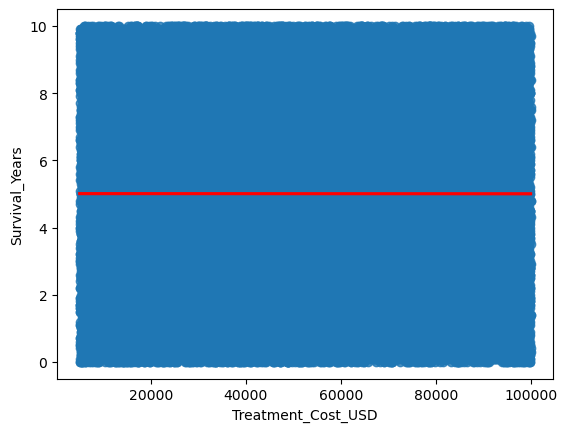

In [187]:
sns.regplot(x=x,y=y, line_kws={"color": "red"})

There is no relationship between Treatment cost and survial years

# Evaluate if higher cancer stages lead to greater treatment costs and reduced survival years

In [190]:
df=data.copy()

In [206]:
stage_order= ['Stage 0','Stage I','Stage II','Stage III','Stage IV']

In [207]:
grouped_stats= df.groupby("Cancer_Stage")[["Treatment_Cost_USD","Survival_Years"]].mean().reset_index()

Treatment Cost vs. Cancer Stage
Null Hypothesis (H0): The average treatment cost is the same across all cancer stages.
Alteernative Hypothesis (H1): At least one stage has a different average cost.

Survival Years vs. Cancer stage
Null Hypothesis (H0): The average survival years are the same across all cancer stages.
Altenative Hypothsis (H1): At least one stage has a different survival duration.


In [219]:
df = data.copy()

stage_order = ['Stage 0', 'Stage I', 'Stage II', 'Stage III', 'Stage IV']

grouped_costs = []
grouped_survival = []

for code, label in enumerate(stage_order):   # code = 0..4, label = stage name
    stage_data = df[df["Cancer_Stage"] == code]
    grouped_costs.append(stage_data["Treatment_Cost_USD"])
    grouped_survival.append(stage_data["Survival_Years"])

print([len(g) for g in grouped_costs])   # each should be in the thousands

[9889, 10046, 10124, 10008, 9933]


In [222]:
# fixing it with the claude
grouped_costs=[]
grouped_survival=[]

for stage in stage_order:
    stage_data=df[df["Cancer_Stage"]==stage]
    cost=stage_data["Treatment_Cost_USD"]
    survival= stage_data["Survival_Years"]
    grouped_costs.append(cost)
    grouped_survival.append(survival)

In [221]:
len(grouped_costs)
    

5

In [230]:
# Check for normality
from scipy.stats import shapiro, f_oneway
normal_cost=0
normal_survival=0

for i in range (len(stage_order)):
    cost_p= shapiro(grouped_costs[i]).pvalue
    surv_p= shapiro(grouped_survival[i]).pvalue
    print(f"{cost_p} for group {i}")
    print(f"{surv_p} for group {i}")
    if cost_p<0.05:
        normal_cost+=1
    if surv_p<0.05:
        normal_survival+=1
print(normal_cost)
print(normal_survival)

1.5471821061637387e-47 for group 0
1.6291039522109283e-47 for group 0
7.306523956950957e-48 for group 1
7.575551046259697e-48 for group 1
8.943579643043388e-48 for group 2
4.041659465829829e-48 for group 2
5.267270033022367e-48 for group 3
1.3648520457944784e-47 for group 3
1.5838640189581322e-47 for group 4
2.2992598289836786e-47 for group 4
5
5


In [229]:
print(normal_cost)
print(normal_survival)

5
5


Group sizes: [9889, 10046, 10124, 10008, 9933]
Stage 0: cost p = 0.0000, survival p = 0.0000
Stage I: cost p = 0.0000, survival p = 0.0000
Stage II: cost p = 0.0000, survival p = 0.0000
Stage III: cost p = 0.0000, survival p = 0.0000
Stage IV: cost p = 0.0000, survival p = 0.0000
Stages with non-normal cost: 5
Stages with non-normal survival: 5


In [231]:
from scipy.stats import kruskal


In [238]:
kruskal_cost= kruskal(*grouped_costs)
kruskal_survival=kruskal(*grouped_survival)

p_cost=kruskal_cost.pvalue
p_survival=kruskal_survival.pvalue

In [239]:
 p_cost

0.4254451689062656

In [240]:
p_survival

0.6033078729984223

==== Kruskal-Wallis Test: Treatment cost across cancer stages ====

P-value: 0.4254
Conclusion: No significant difference in treatment costs among cancer stages.

==== Kruskal-Wallies Test: Survival Years across cancer stages ====

P-value : 0.6033
Conclusion : No significant differnce in survival years among cancer stages.


# Examine whether higher genetic risk amplifies the negative effects of smoking on cancer severity.

Null Hypothesis (H0):
The interaction effect between genetic risk and smoking on cancer severity is not significant.
(Genetic risk does not amplify or alter th effect of smoking. )

Alternative Hypothesis(H1):
The interacction effect between genetic risk and smoking on survival years is significant.
(Genetic risk does amplify or alter the effect of smoking)

In [251]:
import statsmodels.formula.api as smf

model= smf.ols("Target_Severity_Score ~ Genetic_Risk* Smoking",data=data).fit()

model.summary2().tables[1].loc["Genetic_Risk:Smoking"]

Coef.      -0.000228
Std.Err.    0.000471
t          -0.484187
P>|t|       0.628255
[0.025     -0.001150
0.975]      0.000694
Name: Genetic_Risk:Smoking, dtype: float64

In [253]:
p_value=0.628255